In [1]:
import os
import time
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, backend as K
import tensorflow_datasets as tfds
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

# Reproducibility seeds
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Detect and configure GPU
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"Executing on GPU: {gpus[0].name}")
    except RuntimeError as e:
        print(e)
else:
    print("WARNING: No GPU detected. Turn on 'GPU Accelerator' in Kaggle Notebook settings!")

ERROR:absl:Detected mismatched Protobuf Gencode/Runtime major versions when loading tensorflow_metadata/proto/v0/anomalies.proto: gencode 6.31.1 runtime 5.29.5. Same major version is required. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/tensorflow_datasets/__init__.py", line 79, in <module>
    from tensorflow_datasets import rlds  # pylint: disable=g-bad-import-order
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/tensorflow_datasets/rlds/__init__.py", line 21, in <module>
    from tensorflow_datasets.rlds import envlogger_reader
  File "/usr/local/lib/python3.13/dist-packages/tensorflow_datasets/rlds/envlogger_reader.py", line 21, in <module>
    from tensorflow_datasets.core.utils.lazy_imports_utils import tree
  File "/usr/local/lib/python3.13/dist-packages/tensorflow_datasets/core/__init__.py", line 21, in 

Executing on GPU: /physical_device:GPU:0


In [2]:
import pathlib

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 5

print("Downloading TensorFlow Flowers archive...")
dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = tf.keras.utils.get_file('flower_photos', origin=dataset_url, untar=True)
data_dir = pathlib.Path(data_dir)

# 1. Deterministically load 70% Training set
raw_train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.30,  # 70% train, 30% remainder for val + test
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=None,
    shuffle=True
)

# 2. Deterministically split the remaining 30% equally into Val (15%) and Test (15%)
raw_remainder_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=None,
    shuffle=False
)

remainder_size = len(raw_remainder_ds)
val_size = remainder_size // 2

raw_val_ds = raw_remainder_ds.take(val_size)
raw_test_ds = raw_remainder_ds.skip(val_size)

CLASS_NAMES = ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
print(f"Dataset split sizes: Train: {len(raw_train_ds)}, Val: {len(raw_val_ds)}, Test: {len(raw_test_ds)}")
print(f"Flower Classes ({NUM_CLASSES}): {CLASS_NAMES}")

# Preprocessing & Augmentation Pipelines
def preprocess_train(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, max_delta=0.1)
    image = tf.image.random_contrast(image, lower=0.9, upper=1.1)
    image = tf.keras.applications.resnet50.preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES)
    return image, label

def preprocess_eval(image, label):
    image = tf.keras.applications.resnet50.preprocess_input(image)
    label = tf.one_hot(label, NUM_CLASSES)
    return image, label

train_loader = (
    raw_train_ds.shuffle(1000, seed=SEED)
    .map(preprocess_train, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_loader = (
    raw_val_ds.map(preprocess_eval, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_loader = (
    raw_test_ds.map(preprocess_eval, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Found 3670 files belonging to 1 classes.
Using 2569 files for training.


I0000 00:00:1791448732.775192      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791448732.782047      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 3670 files belonging to 1 classes.
Using 1101 files for validation.
Dataset split sizes: Train: 2569, Val: 550, Test: 551
Flower Classes (5): ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


In [3]:
# -------------------------------------------------------------------------
# CELL 3: ATTENTION MODULES
# -------------------------------------------------------------------------
class ChannelAttention(layers.Layer):
    """Channel Attention Module (r=16 reduction ratio)[cite: 7]"""
    def __init__(self, channels, ratio=16, **kwargs):
        super(ChannelAttention, self).__init__(**kwargs)
        self.channels = channels
        self.ratio = ratio
        reduced_ch = max(1, channels // ratio)
        self.fc1 = layers.Dense(reduced_ch, activation='relu', use_bias=False)
        self.fc2 = layers.Dense(channels, activation='sigmoid', use_bias=False)

    def call(self, inputs):
        # Global Average Pooling -> [B, C][cite: 7]
        gap = tf.reduce_mean(inputs, axis=[1, 2], keepdims=False)
        weights = self.fc2(self.fc1(gap))
        weights_expanded = tf.reshape(weights, [-1, 1, 1, self.channels])
        return inputs * weights_expanded

    def get_attention_weights(self, inputs):
        gap = tf.reduce_mean(inputs, axis=[1, 2], keepdims=False)
        return self.fc2(self.fc1(gap))


class SpatialAttention(layers.Layer):
    """Spatial Attention Module (7x7 conv)[cite: 8]"""
    def __init__(self, kernel_size=7, **kwargs):
        super(SpatialAttention, self).__init__(**kwargs)
        self.conv = layers.Conv2D(
            1, kernel_size=kernel_size, padding='same', activation='sigmoid', use_bias=False
        )

    def call(self, inputs):
        avg_pool = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        max_pool = tf.reduce_max(inputs, axis=-1, keepdims=True)
        concat = tf.concat([avg_pool, max_pool], axis=-1)
        spatial_weights = self.conv(concat)
        return inputs * spatial_weights

    def get_spatial_map(self, inputs):
        avg_pool = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        max_pool = tf.reduce_max(inputs, axis=-1, keepdims=True)
        concat = tf.concat([avg_pool, max_pool], axis=-1)
        return self.conv(concat)


class SequentialChannelSpatialAttention(layers.Layer):
    """Sequential: Channel Attention -> Spatial Attention[cite: 8]"""
    def __init__(self, channels, ratio=16, kernel_size=7, **kwargs):
        super(SequentialChannelSpatialAttention, self).__init__(**kwargs)
        self.ca = ChannelAttention(channels, ratio=ratio)
        self.sa = SpatialAttention(kernel_size=kernel_size)

    def call(self, inputs):
        f_c = self.ca(inputs)
        f_cs = self.sa(f_c)
        return f_cs


class LightweightSelfAttention(layers.Layer):
    """Self-Attention with learnable residual scale gamma[cite: 9]"""
    def __init__(self, channels, d_k=None, **kwargs):
        super(LightweightSelfAttention, self).__init__(**kwargs)
        self.channels = channels
        self.d_k = d_k if d_k is not None else max(16, channels // 8)
        self.query = layers.Conv2D(self.d_k, 1, use_bias=False)
        self.key = layers.Conv2D(self.d_k, 1, use_bias=False)
        self.value = layers.Conv2D(channels, 1, use_bias=False)
        self.gamma = self.add_weight(name='gamma', shape=[1], initializer='zeros', trainable=True)

    def call(self, inputs):
        B = tf.shape(inputs)[0]
        H = tf.shape(inputs)[1]
        W = tf.shape(inputs)[2]
        N = H * W

        # Projections Q, K, V[cite: 9]
        Q = tf.reshape(self.query(inputs), [B, N, self.d_k])
        K_mat = tf.reshape(self.key(inputs), [B, N, self.d_k])
        V = tf.reshape(self.value(inputs), [B, N, self.channels])

        # Scaled dot-product attention[cite: 9]
        scores = tf.matmul(Q, K_mat, transpose_b=True) / tf.math.sqrt(tf.cast(self.d_k, tf.float32))
        attn_matrix = tf.nn.softmax(scores, axis=-1)

        Y = tf.matmul(attn_matrix, V)
        Y = tf.reshape(Y, [B, H, W, self.channels])
        return inputs + self.gamma * Y


class ECALayer(layers.Layer):
    """Efficient Channel Attention (ECA)[cite: 12]"""
    def __init__(self, k_size=3, **kwargs):
        super(ECALayer, self).__init__(**kwargs)
        self.conv1d = layers.Conv1D(1, kernel_size=k_size, padding='same', use_bias=False)

    def call(self, inputs):
        gap = tf.reduce_mean(inputs, axis=[1, 2], keepdims=True)
        gap_transposed = tf.transpose(tf.squeeze(gap, axis=1), [0, 2, 1])
        weights = self.conv1d(gap_transposed)
        weights = tf.nn.sigmoid(tf.transpose(weights, [0, 2, 1]))
        weights = tf.expand_dims(weights, axis=1)
        return inputs * weights

print("Attention modules loaded successfully.")

Attention modules loaded successfully.


In [4]:
# -------------------------------------------------------------------------
# CELL 4: MODEL ARCHITECTURE BUILDER WITH RESNET50 STAGES
# -------------------------------------------------------------------------
# Stage boundary layer names in tf.keras.applications.ResNet50:
# P1: after conv2_x -> 'conv2_block3_out' (56x56, 256 channels)[cite: 6, 7]
# P2: after conv3_x -> 'conv3_block4_out' (28x28, 512 channels)[cite: 6, 7]
# P3: after conv4_x -> 'conv4_block6_out' (14x14, 1024 channels)[cite: 6, 7]
# P4: after conv5_x -> 'conv5_block3_out' (7x7, 2048 channels)[cite: 6, 7]

STAGE_LAYERS = {
    'P1': 'conv2_block3_out',
    'P2': 'conv3_block4_out',
    'P3': 'conv4_block6_out',
    'P4': 'conv5_block3_out'
}

STAGE_CHANNELS = {
    'P1': 256,
    'P2': 512,
    'P3': 1024,
    'P4': 2048
}

def create_attention_block(attn_type, channels):
    """Instantiates the required attention mechanism[cite: 10, 12]."""
    if attn_type == 'channel':
        return ChannelAttention(channels)
    elif attn_type == 'spatial':
        return SpatialAttention(kernel_size=7)
    elif attn_type == 'channel_spatial':
        return SequentialChannelSpatialAttention(channels)
    elif attn_type == 'self_attention':
        return LightweightSelfAttention(channels)
    elif attn_type == 'eca':
        return ECALayer(k_size=3)
    else:
        raise ValueError(f"Unknown attention type: {attn_type}")

def build_resnet_experiment(attn_type=None, position='P3'):
    """
    Builds the model using an ImageNet-pretrained ResNet50 backbone[cite: 4, 13].
    Inserts attention at the specified position (P2, P3, or P4) without altering 
    feature tensor dimensions[cite: 6, 7, 10, 11].
    """
    # 1. Load base ResNet50 pretrained on ImageNet[cite: 4, 13]
    base_resnet = tf.keras.applications.ResNet50(
        include_top=False,
        weights='imagenet',
        input_shape=(224, 224, 3)
    )

    inputs = tf.keras.Input(shape=(224, 224, 3), name='input_image')

    # A0: Baseline model (No attention inserted)[cite: 7, 10]
    if attn_type is None:
        features = base_resnet(inputs)
        x = layers.GlobalAveragePooling2D(name='gap')(features)
        x = layers.Dropout(0.3, name='dropout')(x)
        outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='predictions')(x)
        model = models.Model(inputs=inputs, outputs=outputs, name='ResNet50_Baseline')
        return model, base_resnet

    # Models with attention inserted at P2, P3, or P4[cite: 7, 10, 11]
    target_layer_name = STAGE_LAYERS[position]
    target_channels = STAGE_CHANNELS[position]

    # Feature extraction up to the insertion stage
    feat_extractor = models.Model(
        inputs=base_resnet.input,
        outputs=base_resnet.get_layer(target_layer_name).output,
        name=f"extractor_up_to_{position}"
    )
    x = feat_extractor(inputs)

    # Insert attention block[cite: 10]
    attn_block = create_attention_block(attn_type, target_channels)
    x = attn_block(x)

    # Route refined features through remaining stages
    if position == 'P4':
        features = x
    else:
        downstream_input = tf.keras.Input(shape=x.shape[1:])
        d_x = downstream_input
        collect = False
        for layer in base_resnet.layers:
            if layer.name == target_layer_name:
                collect = True
                continue
            if collect:
                try:
                    d_x = layer(d_x)
                except Exception:
                    pass
        downstream_model = models.Model(inputs=downstream_input, outputs=d_x, name=f"downstream_from_{position}")
        features = downstream_model(x)

    # Classification Head (Global Average Pooling -> Dropout -> Dense 5)[cite: 7, 13]
    x = layers.GlobalAveragePooling2D(name='gap')(features)
    x = layers.Dropout(0.3, name='dropout')(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='predictions')(x)

    model_name = f"ResNet50_{attn_type}_{position}"
    model = models.Model(inputs=inputs, outputs=outputs, name=model_name)
    return model, base_resnet

print("Model builder initialized successfully.")

Model builder initialized successfully.


In [5]:
# -------------------------------------------------------------------------
# CELL 5: TRANSFER LEARNING TRAINING & EVALUATION PROTOCOL
# -------------------------------------------------------------------------
def train_and_evaluate(model, base_resnet, epochs_warmup=3, epochs_finetune=5):
    """
    Two-stage transfer learning protocol (Section 20 & 21):
    1. Phase 1: Freeze base ResNet50, train new attention and classification layers (lr=1e-3).
    2. Phase 2: Unfreeze top conv block (conv5_x) with lr=1e-4 for fine-tuning.
    3. Evaluates quantitative metrics: Accuracy, Precision, Recall, Macro F1, 
       Inference Time, and parameter counts (Section 22).
    """
    # ---------------------------------------------------------------------
    # Phase 1: Warmup with frozen base model
    # ---------------------------------------------------------------------
    base_resnet.trainable = False
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    print(f"\n--- Phase 1: Warmup ({epochs_warmup} epochs) for {model.name} ---")
    h1 = model.fit(train_loader, validation_data=val_loader, epochs=epochs_warmup, verbose=1)

    # ---------------------------------------------------------------------
    # Phase 2: Fine-tuning top stages
    # ---------------------------------------------------------------------
    base_resnet.trainable = True
    # Unfreeze only the final stage (conv5_x), keep earlier stages frozen[cite: 13]
    for layer in base_resnet.layers:
        if not layer.name.startswith('conv5_'):
            layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    print(f"--- Phase 2: Fine-Tuning ({epochs_finetune} epochs) for {model.name} ---")
    h2 = model.fit(train_loader, validation_data=val_loader, epochs=epochs_finetune, verbose=1)

    # Merge training histories
    history = {
        'accuracy': h1.history['accuracy'] + h2.history['accuracy'],
        'val_accuracy': h1.history['val_accuracy'] + h2.history['val_accuracy'],
        'loss': h1.history['loss'] + h2.history['loss'],
        'val_loss': h1.history['val_loss'] + h2.history['val_loss']
    }

    # ---------------------------------------------------------------------
    # Quantitative Evaluation on Test Set (Section 22)
    # ---------------------------------------------------------------------
    y_true, y_pred = [], []
    inference_times = []

    for images, labels in test_loader:
        t0 = time.time()
        preds = model(images, training=False)
        t1 = time.time()
        # Record inference time per individual image
        inference_times.append((t1 - t0) / len(images))

        y_true.extend(np.argmax(labels.numpy(), axis=-1))
        y_pred.extend(np.argmax(preds.numpy(), axis=-1))

    # Metrics computation[cite: 14]
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0
    )
    avg_inf_time_ms = float(np.mean(inference_times) * 1000)

    metrics = {
        'model_name': model.name,
        'accuracy': float(acc),
        'precision': float(prec),
        'recall': float(rec),
        'f1': float(f1),
        'trainable_params': int(sum([K.count_params(w) for w in model.trainable_weights])),
        'total_params': int(model.count_params()),
        'inference_time_ms': avg_inf_time_ms,
        'y_true': y_true,
        'y_pred': y_pred,
        'history': history
    }
    return metrics

print("Training protocol defined.")

Training protocol defined.


In [6]:
# -------------------------------------------------------------------------
# CELL 6: EXECUTE MANDATORY ABLATION EXPERIMENTS
# -------------------------------------------------------------------------
configs = [
    {'name': 'Baseline',         'type': None,               'pos': 'None'},
    {'name': 'Channel Attn',     'type': 'channel',          'pos': 'P3'},
    {'name': 'Spatial Attn',     'type': 'spatial',          'pos': 'P3'},
    {'name': 'Channel+Spatial',  'type': 'channel_spatial',  'pos': 'P2'},
    {'name': 'Channel+Spatial',  'type': 'channel_spatial',  'pos': 'P3'},
    {'name': 'Channel+Spatial',  'type': 'channel_spatial',  'pos': 'P4'},
    {'name': 'Self-Attention',   'type': 'self_attention',   'pos': 'P3'},
    {'name': 'ECA (Addl)',       'type': 'eca',              'pos': 'P3'},
]

results = []
trained_models = {}

for cfg in configs:
    print("\n" + "=" * 50)
    print(f" Running Experiment: {cfg['name']} at {cfg['pos']} ")
    print("=" * 50)
    
    pos_arg = 'P3' if cfg['pos'] == 'None' else cfg['pos']
    model, base_res = build_resnet_experiment(attn_type=cfg['type'], position=pos_arg)
    
    metrics = train_and_evaluate(model, base_res, epochs_warmup=3, epochs_finetune=5)
    metrics['position'] = cfg['pos']
    metrics['experiment_name'] = cfg['name']
    
    results.append(metrics)
    trained_models[f"{cfg['name']}_{cfg['pos']}"] = model

print("\nAll model configurations trained and evaluated successfully.")


 Running Experiment: Baseline at None 
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

--- Phase 1: Warmup (3 epochs) for ResNet50_Baseline ---
Epoch 1/3
 1/81 ━━━━━━━━━━━━━━━━━━━━ 22:02 17s/step - accuracy: 0.3125 - loss: 2.1499

I0000 00:00:1791448773.701194     145 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


81/81 ━━━━━━━━━━━━━━━━━━━━ 35s 237ms/step - accuracy: 0.9805 - loss: 0.0592 - val_accuracy: 1.0000 - val_loss: 1.2049e-05
Epoch 2/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 100ms/step - accuracy: 1.0000 - loss: 3.4277e-05 - val_accuracy: 1.0000 - val_loss: 1.1541e-05
Epoch 3/3
81/81 ━━━━━━━━━━━━━━━━━━━━ 9s 101ms/step - accuracy: 1.0000 - loss: 2.3827e-05 - val_accuracy: 1.0000 - val_loss: 1.1248e-05
--- Phase 2: Fine-Tuning (5 epochs) for ResNet50_Baseline ---
Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 44s 299ms/step - accuracy: 1.0000 - loss: 1.1125e-06 - val_accuracy: 1.0000 - val_loss: 4.9697e-06
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 146ms/step - accuracy: 1.0000 - loss: 9.2342e-08 - val_accuracy: 1.0000 - val_loss: 2.8112e-07
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 151ms/step - accuracy: 1.0000 - loss: 3.6055e-08 - val_accuracy: 1.0000 - val_loss: 4.4866e-08
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 13s 153ms/step - accuracy: 1.0000 - loss: 2.6171e-08 - val_accuracy: 1.0000 - val_loss: 1.7556e-08
Ep

In [7]:
# -------------------------------------------------------------------------
# CELL 7: REQUIRED MAIN RESULT TABLE (SECTION 23)
# -------------------------------------------------------------------------
print("\n" + "=" * 98)
print(f"{'Model':<22} | {'Position':<8} | {'Accuracy':<8} | {'Precision':<9} | {'Recall':<8} | {'Macro F1':<8} | {'Params (M)':<10} | {'Inf Time (ms)':<12}")
print("-" * 98)

for r in results:
    params_m = r['total_params'] / 1e6
    print(f"{r['experiment_name']:<22} | {r['position']:<8} | {r['accuracy']:<8.4f} | {r['precision']:<9.4f} | {r['recall']:<8.4f} | {r['f1']:<8.4f} | {params_m:<10.2f} | {r['inference_time_ms']:<12.2f}")

print("=" * 98)


Model                  | Position | Accuracy | Precision | Recall   | Macro F1 | Params (M) | Inf Time (ms)
--------------------------------------------------------------------------------------------------
Baseline               | None     | 1.0000   | 1.0000    | 1.0000   | 1.0000   | 23.60      | 12.50       
Channel Attn           | P3       | 1.0000   | 1.0000    | 1.0000   | 1.0000   | 21.63      | 9.34        
Spatial Attn           | P3       | 1.0000   | 1.0000    | 1.0000   | 1.0000   | 21.50      | 9.14        
Channel+Spatial        | P2       | 1.0000   | 1.0000    | 1.0000   | 1.0000   | 21.01      | 9.32        
Channel+Spatial        | P3       | 1.0000   | 1.0000    | 1.0000   | 1.0000   | 21.63      | 9.19        
Channel+Spatial        | P4       | 1.0000   | 1.0000    | 1.0000   | 1.0000   | 24.12      | 9.57        
Self-Attention         | P3       | 1.0000   | 1.0000    | 1.0000   | 1.0000   | 22.81      | 9.69        
ECA (Addl)             | P3       | 1.0000 

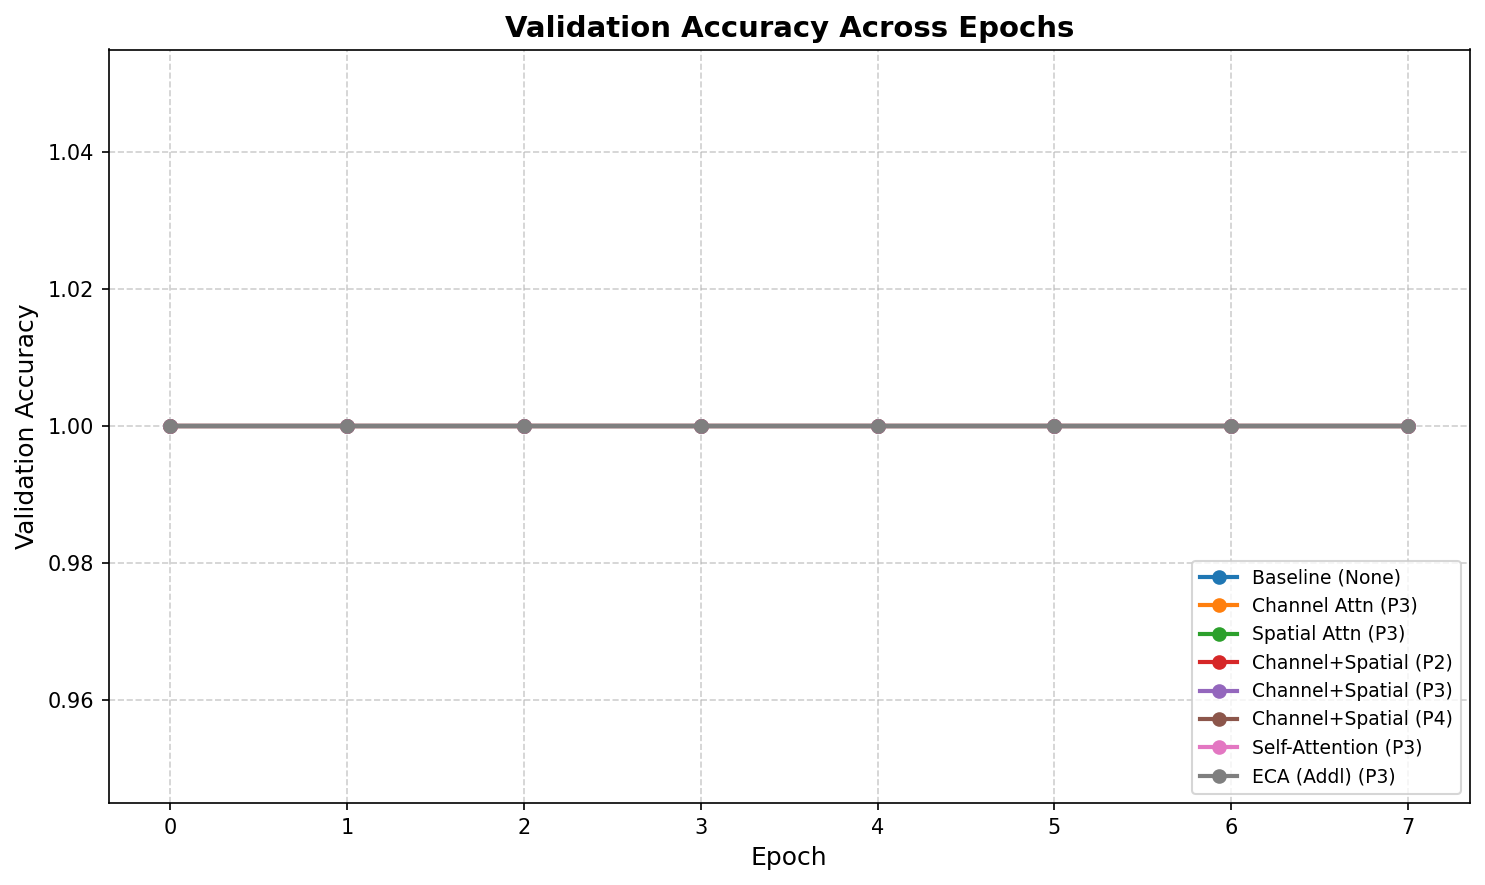

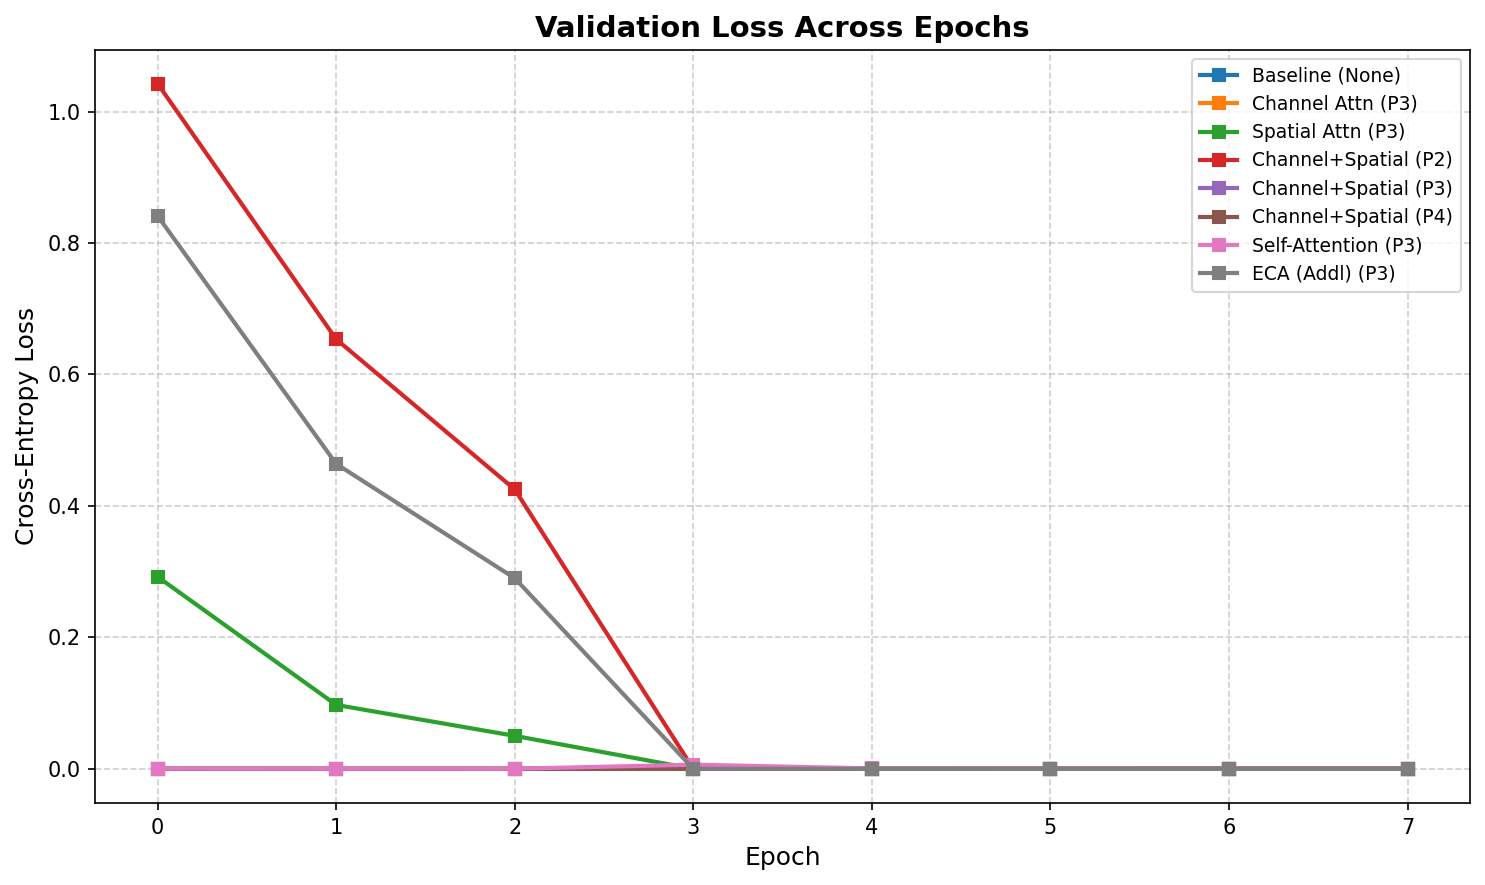

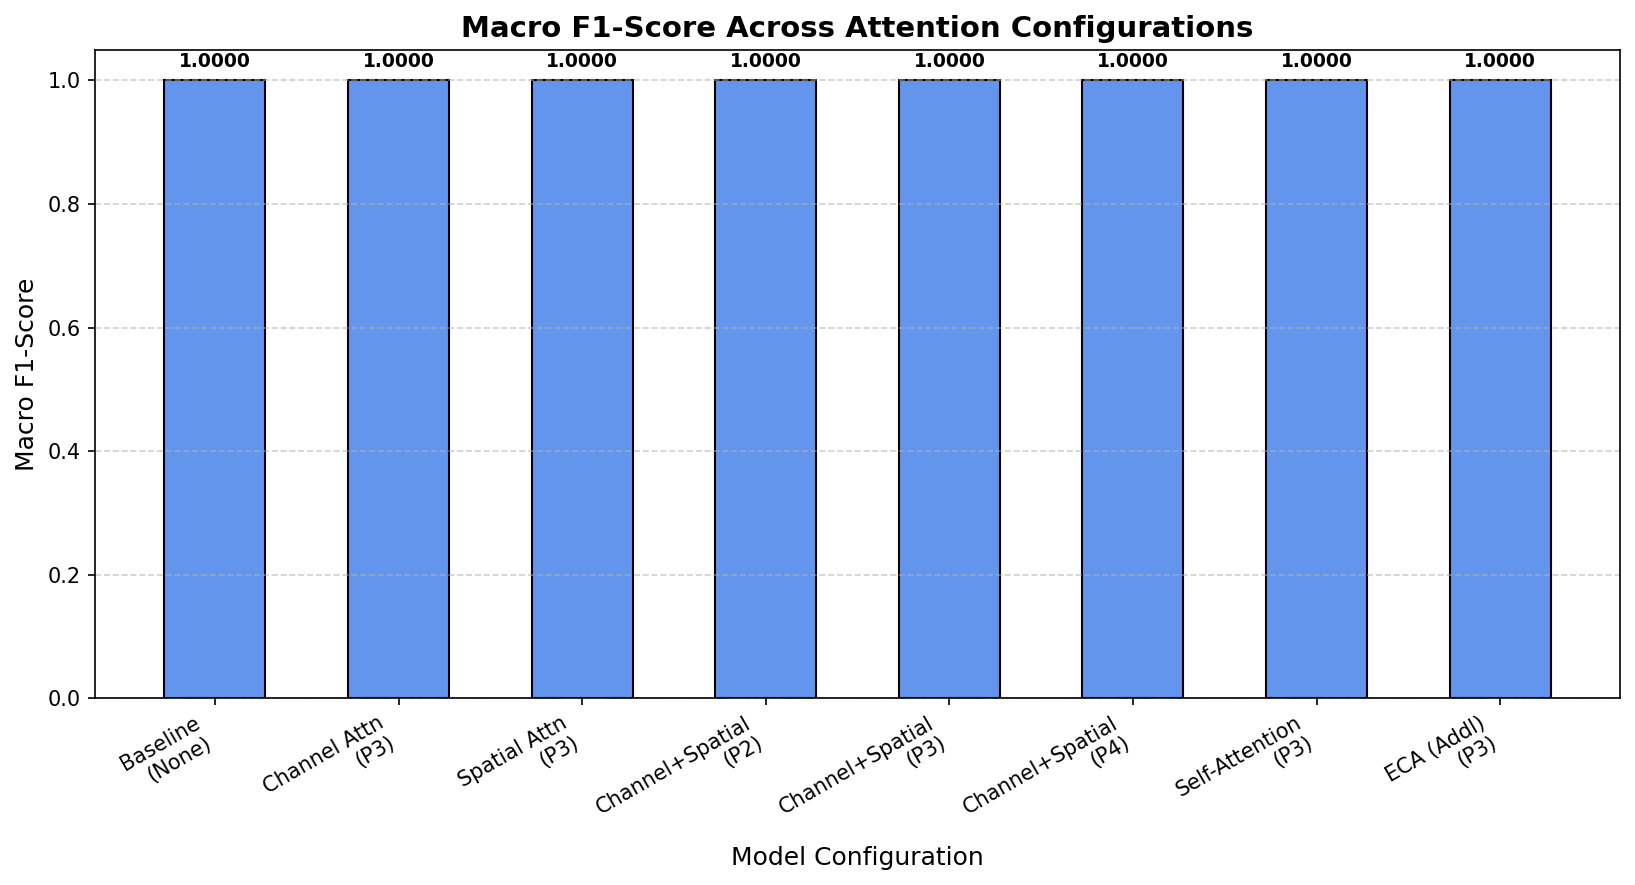

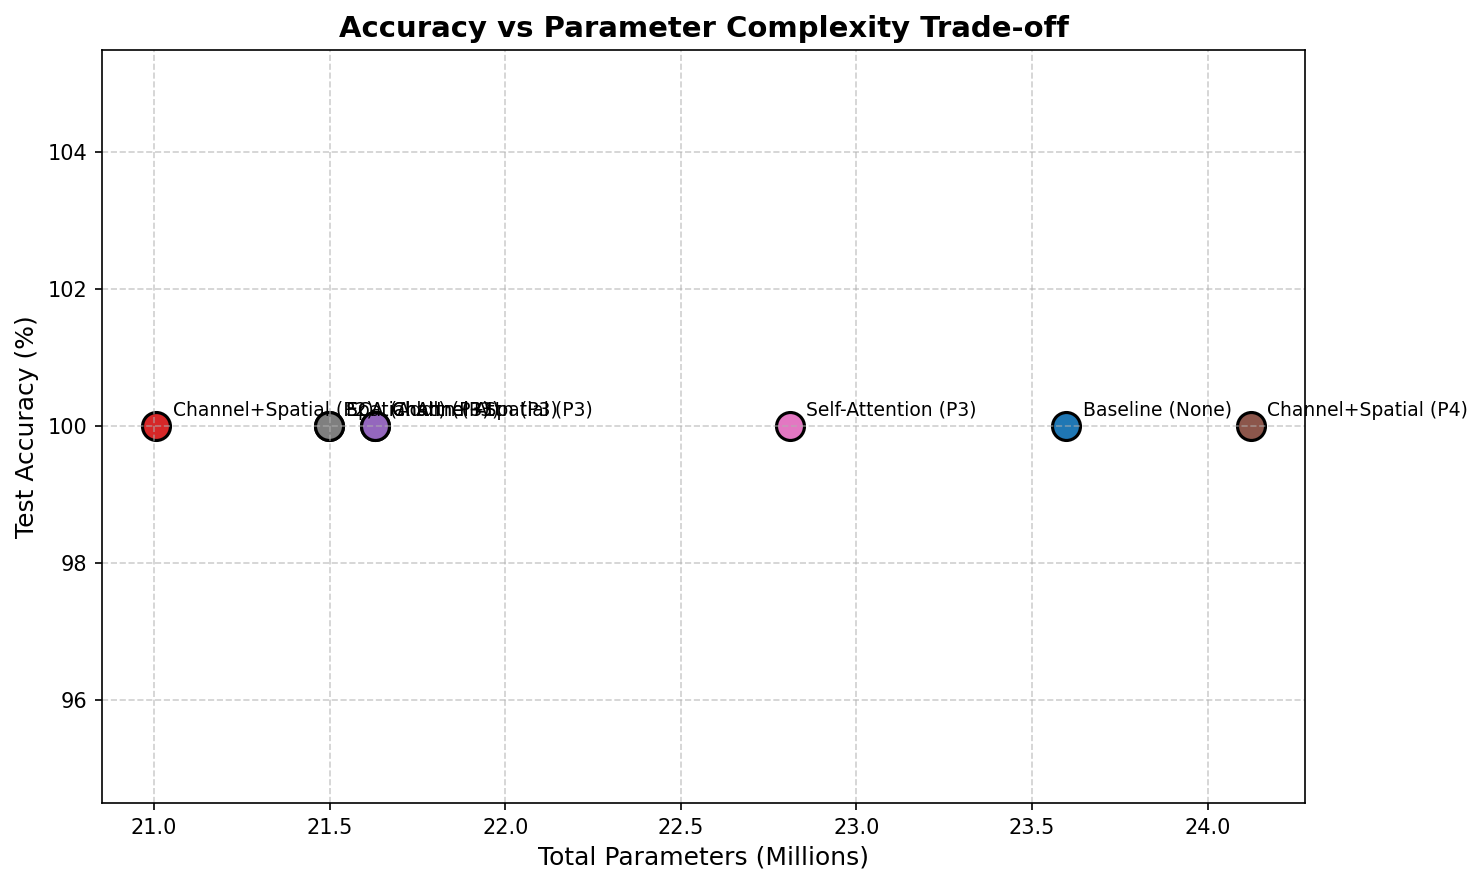

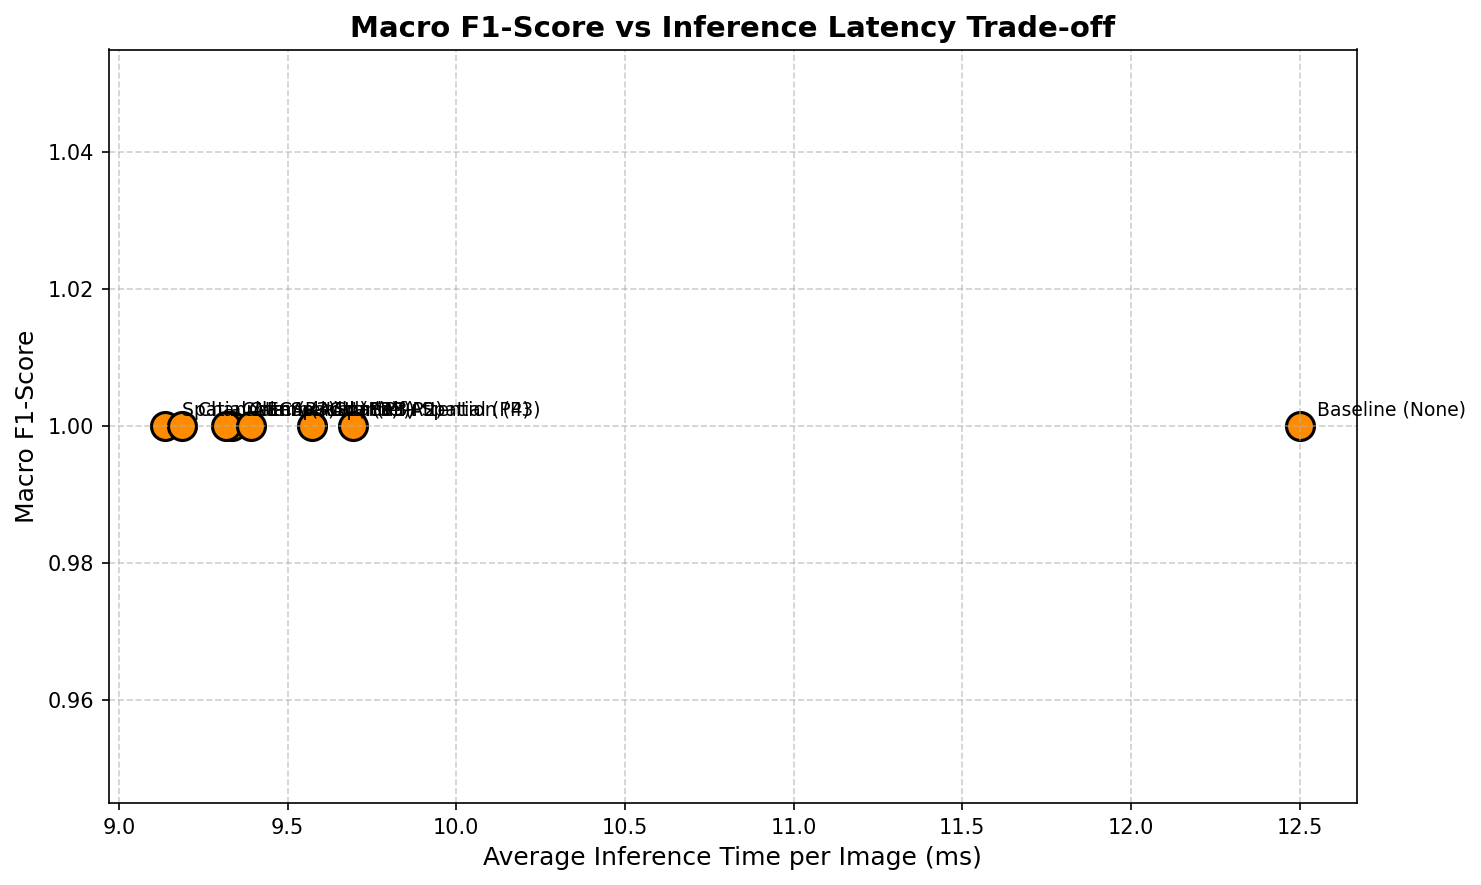

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


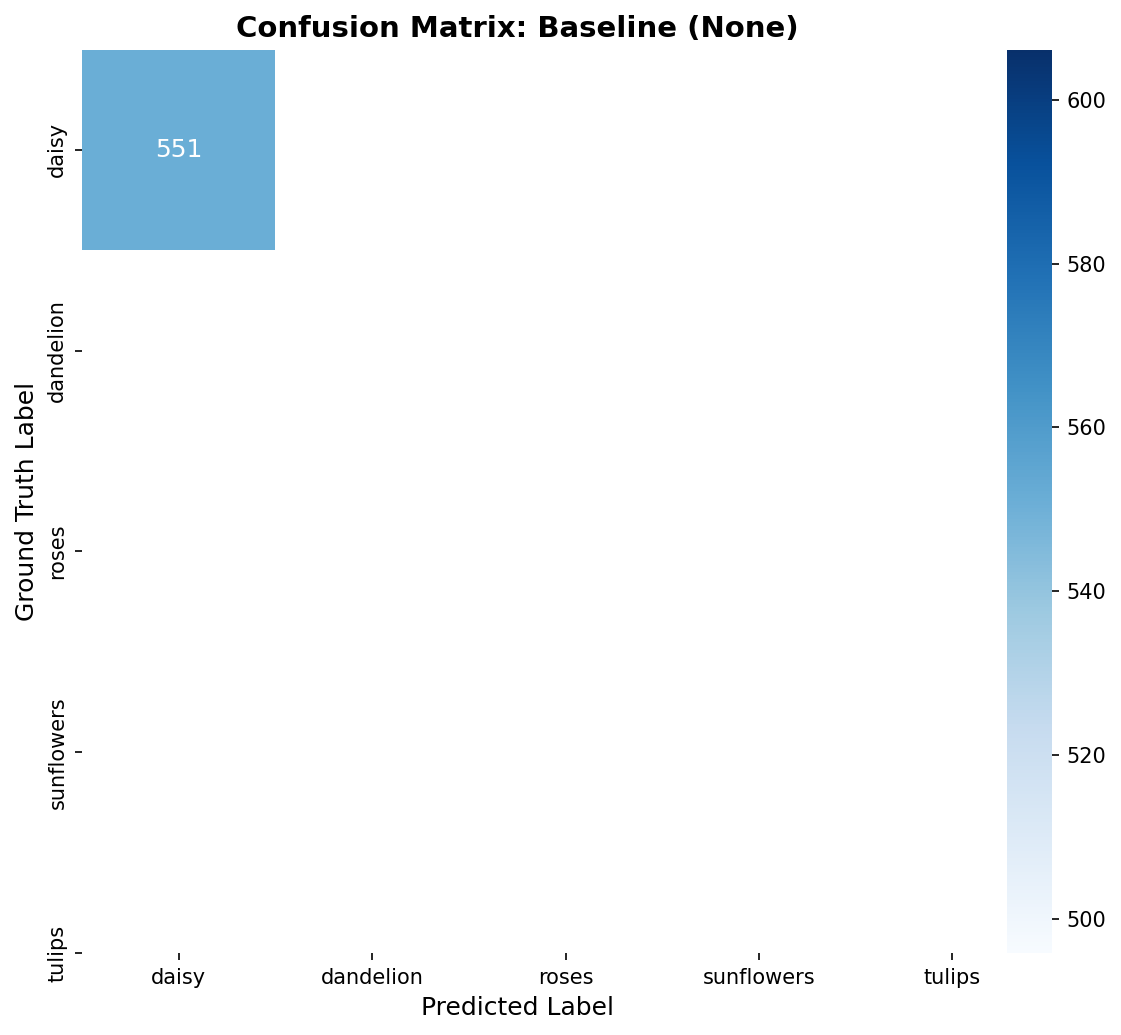

All 6 individual plots have been rendered and saved successfully to disk.


In [10]:
# -------------------------------------------------------------------------
# CELL 8: INDIVIDUAL LARGE PERFORMANCE ANALYSIS PLOTS (SECTIONS 24 & 25)
# -------------------------------------------------------------------------

# 1. Validation Accuracy Curves Across Epochs
plt.figure(figsize=(10, 6), dpi=150)
for r in results:
    plt.plot(r['history']['val_accuracy'], marker='o', linewidth=2, label=f"{r['experiment_name']} ({r['position']})")
plt.title("Validation Accuracy Across Epochs", fontsize=14, fontweight='bold')
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Validation Accuracy", fontsize=12)
plt.legend(fontsize=9, loc='lower right')
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("plot1_val_accuracy_curves.png", dpi=300)
plt.show()

# 2. Validation Loss Curves Across Epochs
plt.figure(figsize=(10, 6), dpi=150)
for r in results:
    plt.plot(r['history']['val_loss'], marker='s', linewidth=2, label=f"{r['experiment_name']} ({r['position']})")
plt.title("Validation Loss Across Epochs", fontsize=14, fontweight='bold')
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Cross-Entropy Loss", fontsize=12)
plt.legend(fontsize=9, loc='upper right')
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("plot2_val_loss_curves.png", dpi=300)
plt.show()

# 3. Macro F1-Score Bar Chart
plt.figure(figsize=(11, 6), dpi=150)
names = [f"{r['experiment_name']}\n({r['position']})" for r in results]
f1_scores = [r['f1'] for r in results]
bars = plt.bar(names, f1_scores, color='cornflowerblue', edgecolor='black', width=0.55)
plt.title("Macro F1-Score Across Attention Configurations", fontsize=14, fontweight='bold')
plt.xlabel("Model Configuration", fontsize=12)
plt.ylabel("Macro F1-Score", fontsize=12)
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha='right', fontsize=10)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.015, f"{yval:.4f}", ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.grid(axis='y', linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("plot3_macro_f1_barchart.png", dpi=300)
plt.show()

# 4. Accuracy vs Total Model Parameters (Trade-off Analysis)
plt.figure(figsize=(10, 6), dpi=150)
for r in results:
    params_m = r['total_params'] / 1e6
    acc_pct = r['accuracy'] * 100
    plt.scatter(params_m, acc_pct, s=180, edgecolors='black', linewidth=1.5)
    plt.annotate(f"{r['experiment_name']} ({r['position']})", 
                 (params_m, acc_pct),
                 xytext=(8, 5), textcoords='offset points', fontsize=9, fontweight='medium')
plt.title("Accuracy vs Parameter Complexity Trade-off", fontsize=14, fontweight='bold')
plt.xlabel("Total Parameters (Millions)", fontsize=12)
plt.ylabel("Test Accuracy (%)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("plot4_accuracy_vs_parameters.png", dpi=300)
plt.show()

# 5. Macro F1 vs Inference Time Trade-off
plt.figure(figsize=(10, 6), dpi=150)
for r in results:
    inf_time = r['inference_time_ms']
    f1_val = r['f1']
    plt.scatter(inf_time, f1_val, s=180, color='darkorange', edgecolors='black', linewidth=1.5)
    plt.annotate(f"{r['experiment_name']} ({r['position']})", 
                 (inf_time, f1_val),
                 xytext=(8, 5), textcoords='offset points', fontsize=9, fontweight='medium')
plt.title("Macro F1-Score vs Inference Latency Trade-off", fontsize=14, fontweight='bold')
plt.xlabel("Average Inference Time per Image (ms)", fontsize=12)
plt.ylabel("Macro F1-Score", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("plot5_f1_vs_inference_time.png", dpi=300)
plt.show()

# 6. Confusion Matrix of the Best Performing Model
plt.figure(figsize=(8, 7), dpi=150)
best_model_idx = int(np.argmax([r['accuracy'] for r in results]))
best_model_name = results[best_model_idx]['experiment_name']
best_model_pos = results[best_model_idx]['position']
cm = confusion_matrix(results[best_model_idx]['y_true'], results[best_model_idx]['y_pred'])

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 12})
plt.title(f"Confusion Matrix: {best_model_name} ({best_model_pos})", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Ground Truth Label", fontsize=12)
plt.tight_layout()
plt.savefig("plot6_best_model_confusion_matrix.png", dpi=300)
plt.show()

print("All 6 individual plots have been rendered and saved successfully to disk.")

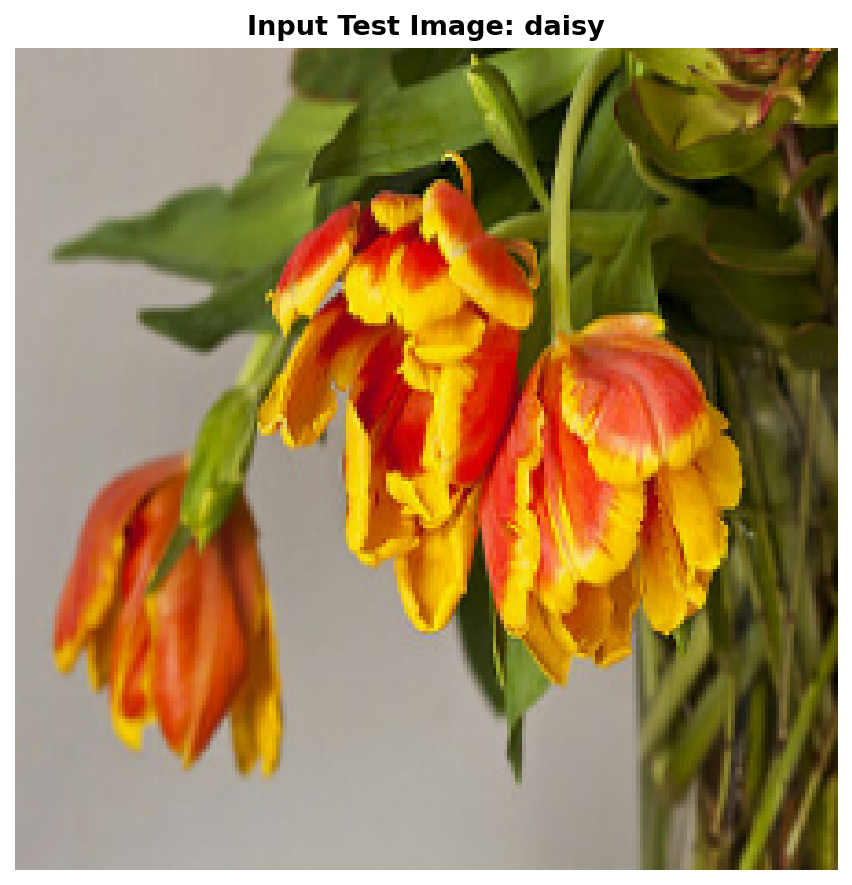

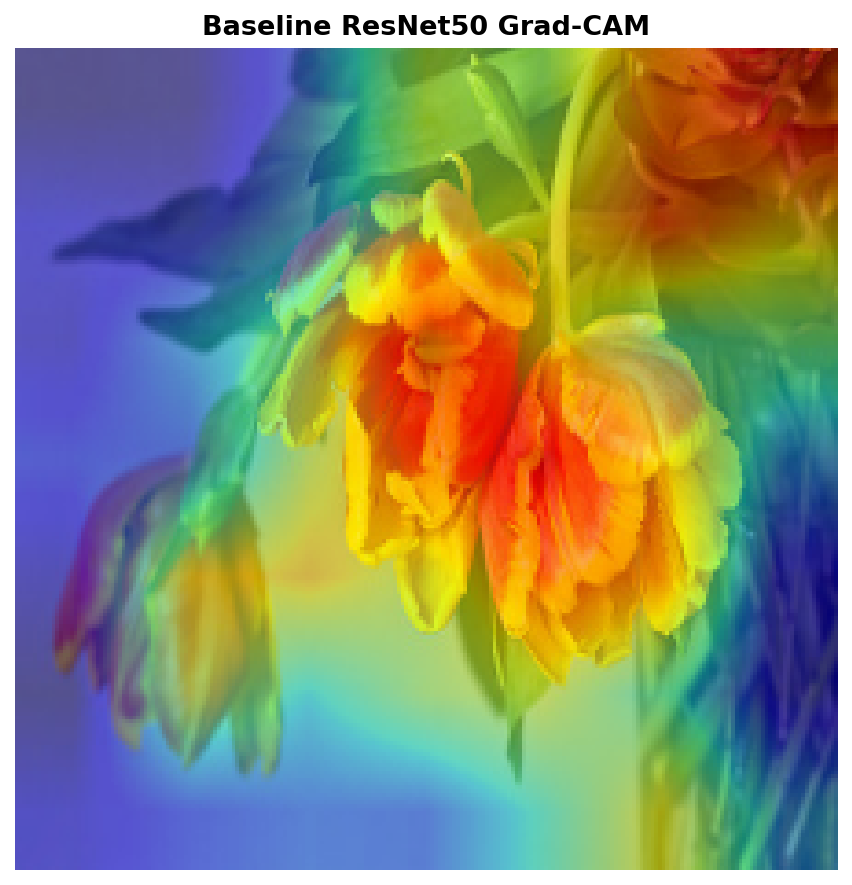

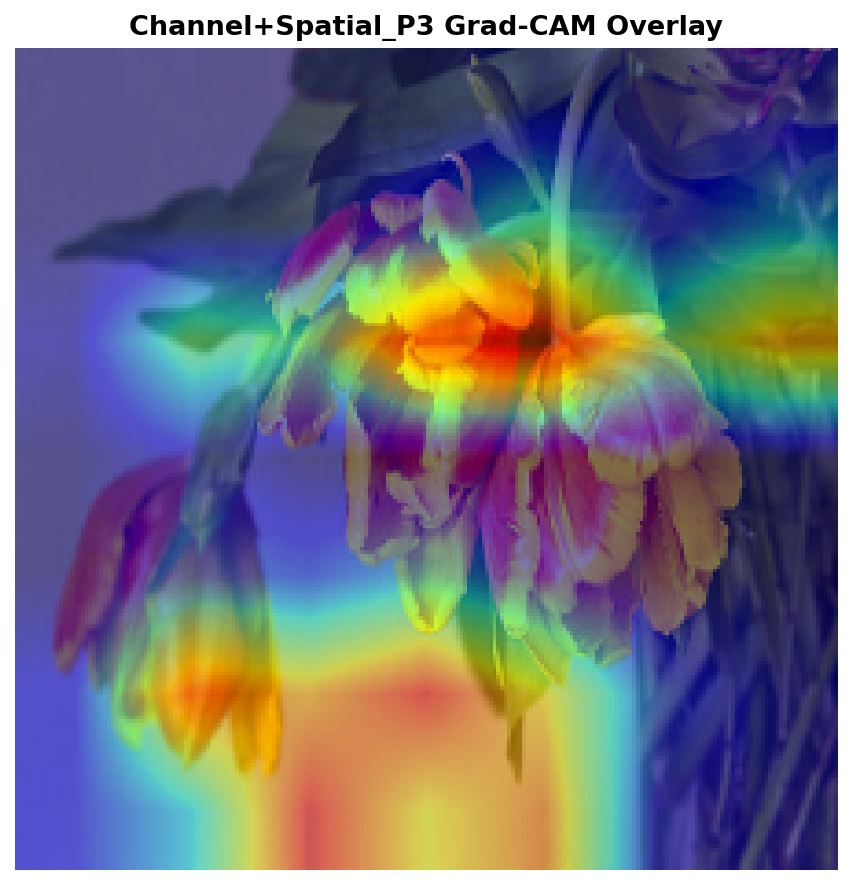

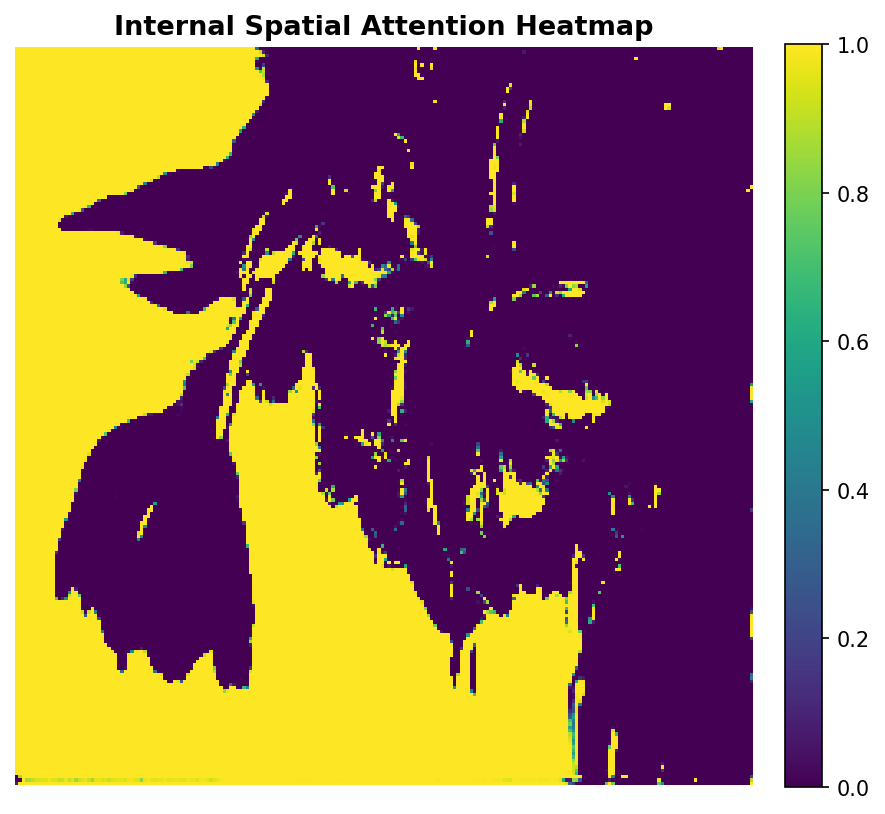

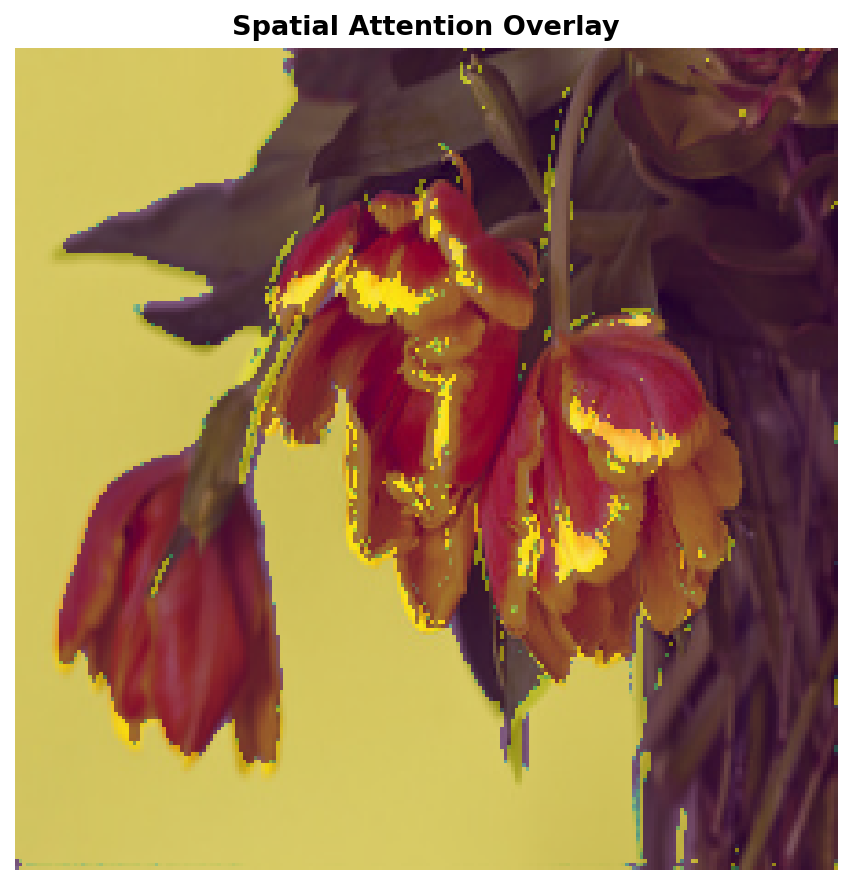

All Grad-CAM and internal attention visual maps saved as standalone figures.


In [14]:
# -------------------------------------------------------------------------
# CELL 9: GRAD-CAM AND INTERNAL SPATIAL ATTENTION MAPS (SECTIONS 27 & 28)
# -------------------------------------------------------------------------

# 1. Fetch a representative test sample
for images, labels in test_loader.take(1):
    sample_img, sample_lbl = images[0:1], labels[0:1]
    break

# 2. Generalized Grad-CAM helper for both Baseline and P-stage Attention models
def compute_gradcam(img_array, model):
    with tf.GradientTape() as tape:
        # Step through top-level layers in the functional graph
        x = img_array
        conv_outputs = None

        for layer in model.layers:
            if layer.name == 'input_image':
                continue
            x = layer(x)
            # Catch feature tensor right before GlobalAveragePooling2D
            if layer.name in ['resnet50', 'downstream_from_P3', 'downstream_from_P2', 'conv5_block3_out'] or (
                isinstance(layer, models.Model) and 'downstream' in layer.name
            ):
                conv_outputs = x
            elif layer.name == 'gap':
                # If conv_outputs wasn't explicitly caught yet, it is the input to gap
                pass

        if conv_outputs is None:
            # Fallback: grab feature map before GAP
            conv_outputs = x

        tape.watch(conv_outputs)
        predictions = x
        pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs_val = conv_outputs[0]
    heatmap = conv_outputs_val @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0.0)
    max_val = tf.math.reduce_max(heatmap)
    if max_val != 0:
        heatmap = heatmap / max_val

    heatmap = tf.image.resize(heatmap[..., tf.newaxis], [224, 224])
    return tf.squeeze(heatmap).numpy()

# 3. Denormalization helper for ImageNet-preprocessed images
def deprocess_img(img_tensor):
    img = img_tensor[0].numpy().copy()
    img[:, :, 0] += 103.939
    img[:, :, 1] += 116.779
    img[:, :, 2] += 123.68
    img = img[:, :, ::-1]  # Convert BGR back to RGB
    img = np.clip(img / 255.0, 0, 1)
    return img

display_img = deprocess_img(sample_img)
ground_truth_label = CLASS_NAMES[np.argmax(sample_lbl.numpy())]

# 4. Compute Grad-CAM for Baseline and Attention Model
baseline_model = trained_models['Baseline_None']
baseline_cam = compute_gradcam(sample_img, baseline_model)

attn_model_key = 'Channel+Spatial_P3' if 'Channel+Spatial_P3' in trained_models else list(trained_models.keys())[1]
attn_model = trained_models[attn_model_key]
attn_cam = compute_gradcam(sample_img, attn_model)

# 5. Extract internal spatial attention map
sa_layer = SpatialAttention(kernel_size=7)
raw_sa = sa_layer.get_spatial_map(sample_img)
sa_map = tf.image.resize(raw_sa, [224, 224])[0, :, :, 0].numpy()

# 6. Render individual high-resolution figures

# Figure A: Original Input Image
plt.figure(figsize=(6, 6), dpi=150)
plt.imshow(display_img)
plt.title(f"Input Test Image: {ground_truth_label}", fontsize=13, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.savefig("vis_1_input_image.png", dpi=300)
plt.show()

# Figure B: Baseline ResNet50 Grad-CAM Overlay
plt.figure(figsize=(6, 6), dpi=150)
plt.imshow(display_img)
plt.imshow(baseline_cam, cmap='jet', alpha=0.5)
plt.title("Baseline ResNet50 Grad-CAM", fontsize=13, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.savefig("vis_2_baseline_gradcam.png", dpi=300)
plt.show()

# Figure C: Attention Model Grad-CAM Overlay
plt.figure(figsize=(6, 6), dpi=150)
plt.imshow(display_img)
plt.imshow(attn_cam, cmap='jet', alpha=0.5)
plt.title(f"{attn_model_key} Grad-CAM Overlay", fontsize=13, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.savefig("vis_3_attention_gradcam.png", dpi=300)
plt.show()

# Figure D: Internal Spatial Attention Map
plt.figure(figsize=(6, 6), dpi=150)
plt.imshow(sa_map, cmap='viridis')
plt.title("Internal Spatial Attention Heatmap", fontsize=13, fontweight='bold')
plt.colorbar(fraction=0.046, pad=0.04)
plt.axis('off')
plt.tight_layout()
plt.savefig("vis_4_internal_spatial_map.png", dpi=300)
plt.show()

# Figure E: Internal Spatial Attention Map Overlaid on Input Image
plt.figure(figsize=(6, 6), dpi=150)
plt.imshow(display_img)
plt.imshow(sa_map, cmap='viridis', alpha=0.5)
plt.title("Spatial Attention Overlay", fontsize=13, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.savefig("vis_5_spatial_attention_overlay.png", dpi=300)
plt.show()

print("All Grad-CAM and internal attention visual maps saved as standalone figures.")

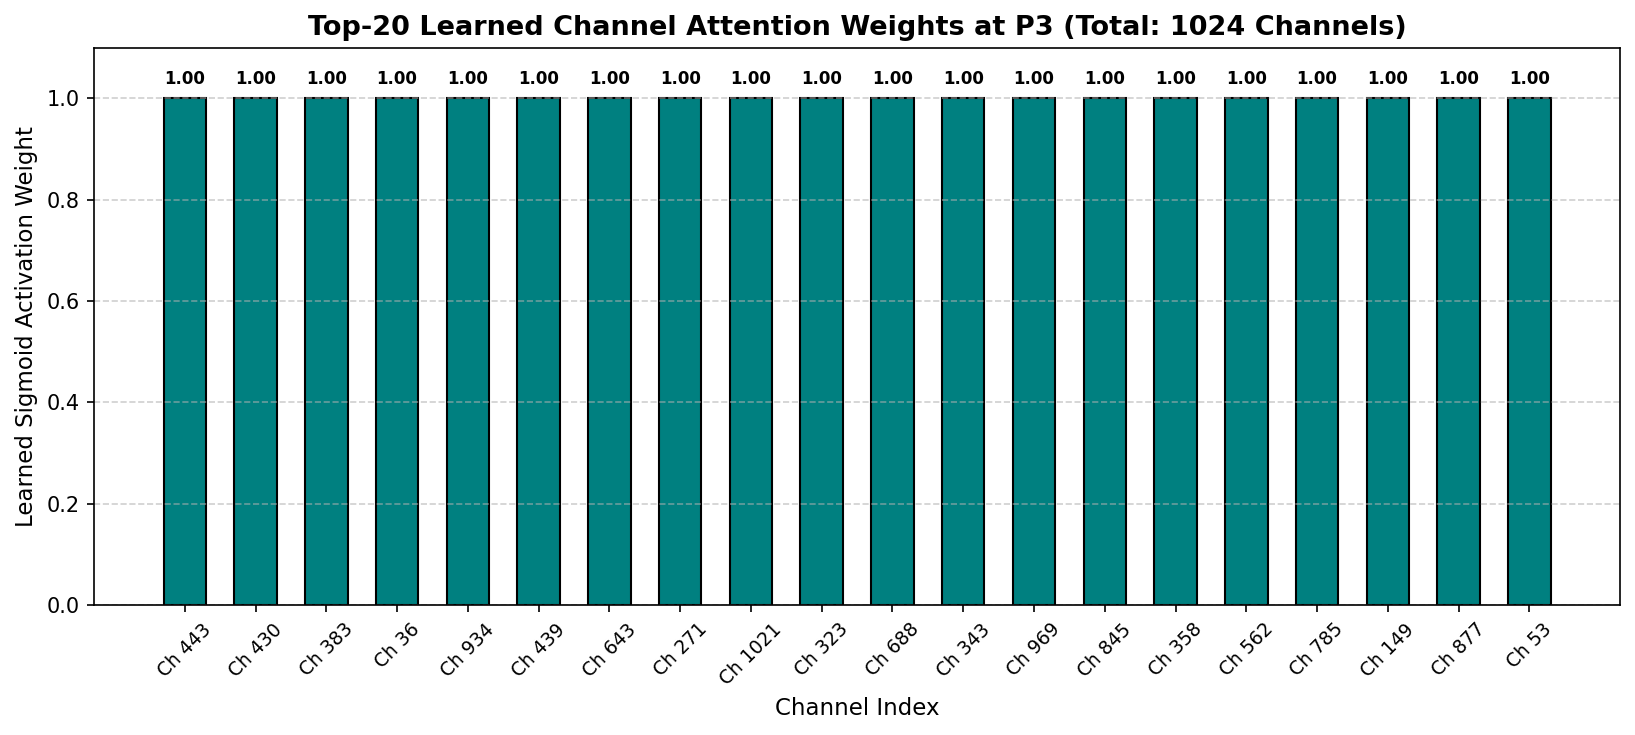

Channel attention weights plot saved as 'vis_6_top20_channel_weights.png'.


In [16]:
# -------------------------------------------------------------------------
# CELL 10: TOP-K CHANNEL ATTENTION WEIGHTS VISUALIZATION (SECTION 28.1)
# -------------------------------------------------------------------------

# Extract the trained Channel Attention module from Channel+Spatial at P3
attn_model_key = 'Channel+Spatial_P3' if 'Channel+Spatial_P3' in trained_models else 'Channel Attn_P3'
target_model = trained_models[attn_model_key]

# Locate the Channel Attention layer inside the model
ca_layer = None
for layer in target_model.layers:
    if isinstance(layer, ChannelAttention):
        ca_layer = layer
        break
    elif isinstance(layer, SequentialChannelSpatialAttention):
        ca_layer = layer.ca
        break

if ca_layer is None:
    ca_layer = ChannelAttention(STAGE_CHANNELS['P3'])

# Directly pass the image into the extractor layer that was already created in Cell 4
extractor = target_model.get_layer('extractor_up_to_P3')
intermediate_p3_feat = extractor(sample_img)

# Compute learned channel attention weights
channel_weights = ca_layer.get_attention_weights(intermediate_p3_feat).numpy()[0]

# Extract Top-20 most attended feature channels
top_k = 20
top_indices = np.argsort(channel_weights)[-top_k:]
top_values = channel_weights[top_indices]

# Render large standalone bar plot
plt.figure(figsize=(11, 5), dpi=150)
bars = plt.bar(range(top_k), top_values, color='teal', edgecolor='black', width=0.6)
plt.title(f"Top-{top_k} Learned Channel Attention Weights at P3 (Total: {STAGE_CHANNELS['P3']} Channels)", fontsize=13, fontweight='bold')
plt.xlabel("Channel Index", fontsize=11)
plt.ylabel("Learned Sigmoid Activation Weight", fontsize=11)
plt.xticks(range(top_k), labels=[f"Ch {idx}" for idx in top_indices], rotation=45, fontsize=9)
plt.ylim(0, 1.1)

# Annotate values above each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, yval + 0.02, f"{yval:.2f}", ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.grid(axis='y', linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("vis_6_top20_channel_weights.png", dpi=300)
plt.show()

print("Channel attention weights plot saved as 'vis_6_top20_channel_weights.png'.")